![Banner](../images/09_07_banner_rs_texture.png)


# Texture Analysis of Landsat Imagery: Transform-Based (Spectral) Methods

A texture is a pattern that repeats at certain spatial frequencies and in certain directions.


## Overview

Transform- based methods make frequency, orientation and scale explicit by moving the image into another domain: the Fourier domain, a bank of Gabor filters, or a wavelet decomposition. This notebook explains the theory of the three transforms, computes them on the NIR band of a Landsat 9 scene over Las Vegas with `geolattice.rsense.texture`, maps the dominant orientation of the street grid and the mountain ridges, and tests what transform-based texture adds to spectral information.


### Image texture in brief

Spectral values tell us *what* a pixel is made of; **texture** tells us *how pixel values are arranged*
around it. Texture is the spatial variation of gray levels inside a neighbourhood and describes
properties such as smoothness, coarseness, regularity, directionality and contrast. Haralick,
Shanmugam and Dinstein (1973) noted that tone and texture are always present together in an image, but
one may dominate the other depending on the scene.

At Landsat's 30 m resolution many land-cover classes overlap spectrally: urban fabric, bare soil and
rock are all bright and dry in an arid scene; crop types or forest stands can share the same NDVI;
rough terrain mixes lit slopes and shadow within a few pixels. Texture separates such classes because
it responds to *pattern*, not only to *brightness*, and texture layers are routinely stacked with bands
and indices as predictors in land-cover classification, urban mapping, forest-structure modelling and
soil mapping.

Methods are usually grouped into six families. This series covers them in five notebooks:

| Notebook | Family | Methods |
|---|---|---|
| 09_07_01 | [Statistical and structural texture](09_07_01_texture_analysis_of_landsat_imagery_statistical_and_structural_methods.ipynb) | First-order statistics, GLCM, GLRLM, edge density, lacunarity |
| 09_07_02 | **Transform-based (spectral) texture** (this notebook) | Fourier power spectrum, Gabor filter bank, Haar wavelets |
| 09_07_03 | [Local pattern-based texture](09_07_03_texture_analysis_of_landsat_imagery_local_pattern_based_methods_lbp.ipynb) | Local Binary Patterns (LBP) |
| 09_07_04 | [Model-based texture](09_07_04_texture_analysis_of_landsat_imagery_model_based_methods.ipynb) | Markov Random Field energy, fractal dimension, autoregressive model |
| 09_07_05 | [Deep-learning-based texture](09_07_05_texture_analysis_of_landsat_imagery_deep_learning_based_methods.ipynb) | Pretrained CNN feature maps |

All methods come from `geolattice.rsense.texture`. Every function accepts a 2-D `xr.DataArray` (or NumPy
array) and returns a georeferenced result with the same shape as the input; inputs with leading
dimensions (band, time, polarization) are processed slice by slice, and multi-feature methods return an
`xr.Dataset` with one variable per feature.


### Theory: texture as frequency, orientation and scale

**1. Fourier power spectrum.** The 2-D discrete Fourier transform writes an $M \times M$ tile $g(x, y)$
as a sum of sinusoids:

$$F(u, v) = \sum_{x=0}^{M-1}\sum_{y=0}^{M-1} g(x, y)\, e^{-2\pi i (ux + vy)/M}.$$

The power spectrum $|F(u,v)|^2$ tells how much variance the tile has at each spatial frequency
$(u, v)$. The **distance from the centre** of the (centred) spectrum, $\rho = \sqrt{u^2 + v^2}$, is the
spatial frequency (fine patterns far from the centre, coarse patterns near it), and the **angle**
$\phi = \arctan(v/u)$ is the orientation of the pattern (perpendicular to the stripes). Summing the power
in concentric rings gives a rotation-invariant description of coarseness (Rosenfeld and Troy 1970;
Weszka, Dyer and Rosenfeld 1976):

$$E_k = \frac{\sum_{\rho \in \text{ring } k} |F|^2}{\sum |F|^2}.$$

Each tile is multiplied by a 2-D Hann window before the transform, to suppress the artificial edges
created by cutting the tile out of the image (spectral leakage).

**2. Gabor filters.** A Gabor filter is a sinusoid of frequency $f$ and orientation $\theta$ under a
Gaussian envelope (Gabor 1946; Daugman 1985):

$$h(x, y) = \exp\!\left(-\frac{x'^2 + y'^2}{2\sigma^2}\right)\exp\!\left(2\pi i f x'\right),\qquad
x' = x\cos\theta + y\sin\theta,\; y' = -x\sin\theta + y\cos\theta.$$

Convolving the image with $h$ gives a complex response whose **energy** $|g * h|^2$ is high where the
image contains a pattern of that frequency and orientation. A bank of filters (several $f$ and
$\theta$) is a localized Fourier analysis: unlike the global spectrum of a tile, every pixel gets its
own frequency-orientation description. Gabor filters resemble the receptive fields of simple cells in
the mammalian visual cortex, which is one reason they work well for texture segmentation (Jain and
Farrokhnia 1991).

**3. Wavelets.** The discrete wavelet transform (Mallat 1989) splits an image into an approximation and
detail at successive scales. One level of the 2-D Haar transform takes each 2 × 2 block $\{a, b; c, d\}$
and returns

$$LL = \tfrac{a+b+c+d}{2},\quad LH = \tfrac{a-b+c-d}{2},\quad HL = \tfrac{a+b-c-d}{2},\quad HH = \tfrac{a-b-c+d}{2},$$

each at half the resolution. `LL` is a smoothed image that feeds the next level; `LH` and `HL` hold
detail along the two image axes and `HH` diagonal detail. Level 1 describes 30 m detail, level 2 60 m,
level 3 120 m, and so on. The local energy of each subband is a scale- and orientation-specific texture
feature.

| Transform | Localization | Frequency resolution | Orientation | Cost |
|---|---|---|---|---|
| Fourier rings | One tile at a time | Fine (many rings) | Averaged out (rings) | Low (FFT) |
| Gabor bank | Every pixel | Few chosen frequencies | Explicit, chosen angles | Medium (one convolution per filter) |
| Haar wavelet | Every pixel | Octaves (×2 per level) | 2 axes + diagonal | Very low |


### Applications

| Application | Method | Why it works |
|---|---|---|
| Row-crop, orchard and vineyard mapping | Fourier rings, Gabor | Planting rows produce a sharp peak at one frequency and direction |
| Urban structure and building density | Gabor energy, wavelet detail | Street grids repeat at block-scale frequencies in two directions |
| Ocean waves and swell from SAR | Fourier spectrum | The wave spectrum gives wavelength and direction directly |
| Geological lineaments and fold belts | Oriented Gabor filters | Ridges, dykes and faults have a preferred strike |
| Sand-dune morphometry | Fourier spectrum | Dune spacing and crest orientation are spectral peaks |
| Forest canopy texture | Wavelet energy, Fourier | Crown size sets the dominant scale of variation |
| Multi-scale land-cover classification | Wavelet energy at several levels | Classes differ at different scales |


### Learning objectives

1. Explain how the Fourier power spectrum, Gabor filters and Haar wavelets describe frequency,
   orientation and scale.
2. Read a 2-D power spectrum and relate ring energy to texture coarseness.
3. Compute Fourier ring, Gabor and wavelet texture on Landsat NIR with `geolattice.rsense.texture`.
4. Map the dominant orientation and anisotropy of texture with a Gabor bank.
5. Compare transform-based texture signatures and test what they add to an unsupervised
   classification.


### Data

| File | Content |
|---|---|
| `data/blue.tif` | Landsat 9 OLI-2 band 2 (blue), Collection 2 Level-2 surface reflectance DN |
| `data/green.tif` | Landsat 9 OLI-2 band 3 (green) |
| `data/red.tif` | Landsat 9 OLI-2 band 4 (red) |
| `data/nir.tif` | Landsat 9 OLI-2 band 5 (NIR) |

All four bands come from the Las Vegas scene used in the Landsat module
([09_02_04_landsat_half_a_century_of_earth_observation](../09_02_optical/09_02_04_landsat_half_a_century_of_earth_observation.ipynb)): path 39, row 35, 8 July 2024, UTM zone
11N (EPSG:32611), 30 m, 1,679 × 1,512 pixels, stored as unsigned 16-bit DN with 0 as the fill value.


### Contents

1. Setup
2. Loading the Landsat bands and the study window
3. Fourier power spectrum and ring energy
4. Gabor filter bank
5. Haar wavelet decomposition
6. Application: orientation mapping
7. Application: texture signatures and clustering
8. Summary and exercises


## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Setup: silence noisy warnings, import the libraries and choose the array backend.
import warnings
warnings.filterwarnings("ignore", category=UserWarning)  # hide routine library warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)  # e.g. 'mean of empty slice' in all-NaN windows
warnings.filterwarnings("ignore", category=FutureWarning)  # deprecation notices from pandas and xarray

import time  # time each texture computation
from pathlib import Path  # portable file paths

import numpy as np  # arrays
import pandas as pd  # tables
import xarray as xr  # labelled rasters (DataArray, Dataset)
import rasterio  # GeoTIFF reading and writing
import matplotlib.pyplot as plt  # figures
from matplotlib.patches import Rectangle  # draw the study-window rectangle

import geolattice.rsense as rs  # GeoLattice remote sensing: reading, scaling and plotting
from geolattice.rsense import texture as tx  # GeoLattice texture functions

rasterio.Env(CPL_LOG="/dev/null").__enter__()  # silence GDAL log messages for the whole session
plt.rcParams.update({"figure.dpi": 90})  # figure resolution
# "cpu" keeps every array on NumPy; the texture functions copy GPU arrays to the CPU anyway.
# report the GeoLattice version and switch to the NumPy (CPU) backend
print("geolattice.rsense", rs.__version__, "| backend:", rs.set_backend("cpu"))

geolattice.rsense 0.3.49 | backend: cpu


## Loading the Landsat bands and the study window

The files hold raw Collection 2 Level-2 digital numbers (DN). We read them with `rs.read`, put them in
one `xr.Dataset`, and convert them to surface reflectance with `rs.optical.scale`, which applies
**reflectance = DN × 0.0000275 − 0.2** and turns the fill value 0 into NaN.

Window-based texture is easier to see, and much faster to compute, on a smaller area. We work on a
512 × 512 pixel window (15.4 × 15.4 km) on the eastern edge of Las Vegas that contains four very
different surfaces:

- the regular **street grid** of the city (west),
- the smooth, bare **alluvial fan** below Frenchman Mountain (centre),
- the folded sedimentary **ridges of Frenchman Mountain** (east),
- the vegetated channel of the **Las Vegas Wash** (south), red in colour infrared.


In [2]:
# 1. Read each band as a 2-D DataArray (drop the singleton "band" dimension).
DATA = Path("../../../../Data/00_shared/data_remote_sensing/landsat9_vegas_20240708/LC09_L2SP_039035_20240708_02_T1")  # Landsat 9 scene, path 39 row 35, 8 July 2024
BANDS = ["blue", "green", "red", "nir"]  # the four bands used in this notebook
# read each band; masked=False keeps the raw digital numbers (DN)
ls_dn = xr.Dataset({b: rs.read(DATA / f"{b}.tif", masked=False).squeeze("band", drop=True)
                    for b in BANDS})  # one variable per band
ls_dn = ls_dn.rio.write_crs(ls_dn["red"].rio.crs)  # store the CRS on the Dataset as a whole

# 2. Scale DN to surface reflectance (fill value 0 becomes NaN) and clip to [1e-4, 1].
# Landsat Collection 2 scale and offset: DN -> reflectance
ls = rs.optical.scale(ls_dn, sensor="landsat").clip(min=1e-4, max=1.0)
# scene size, pixel size and CRS
print(f"{ls.rio.width} x {ls.rio.height} pixels at {ls.rio.resolution()[0]:.0f} m, CRS {ls.rio.crs}")

# 3. Study window (rows/columns in the full scene) and the NIR band used for most texture measures.
WIN = dict(y=slice(500, 1012), x=slice(900, 1412))  # 512 x 512 pixel window (rows 500-1011, columns 900-1411)
sub = ls.isel(WIN)  # all four bands inside the window
nir = sub["nir"]  # the NIR band of the window

1679 x 1512 pixels at 30 m, CRS EPSG:32611


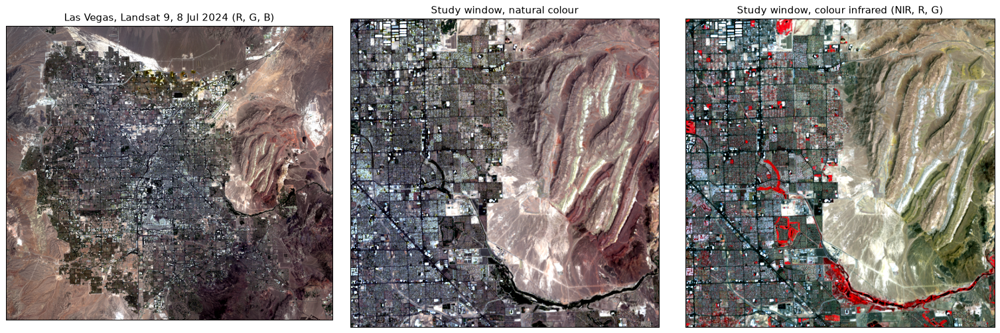

In [3]:
# Where the study window lies, and how it looks in natural colour and colour infrared.
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))  # three panels side by side
# full scene, red-green-blue
rs.viz.plot_rgb(ls, "true_color", ax=axes[0], title="Las Vegas, Landsat 9, 8 Jul 2024 (R, G, B)")
# the study window in yellow (x = column 900, y = row 500)
axes[0].add_patch(Rectangle((900, 500), 512, 512, fill=False, ec="yellow", lw=2))
# the window in natural colour
rs.viz.plot_rgb(sub, "true_color", ax=axes[1], title="Study window, natural colour")
# NIR, red, green: vegetation appears red
rs.viz.plot_rgb(sub, "false_color", ax=axes[2], title="Study window, colour infrared (NIR, R, G)")
for a in axes:  # hide the pixel ticks
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()  # arrange and draw

## Fourier power spectrum and ring energy

### Reading a power spectrum: synthetic stripes

Three synthetic 64 × 64 images with stripes of period 16, 8 and 4 pixels, and one with random noise.
The spectrum of a stripe pattern is a pair of bright points; their distance from the centre grows as
the period shrinks, and they lie on a line **perpendicular** to the stripes.


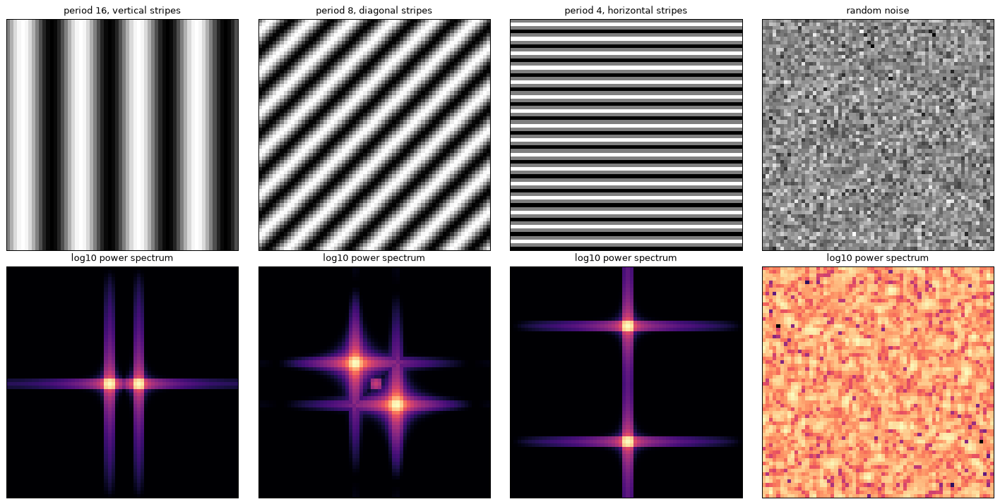

In [4]:
# Synthetic textures and their Fourier power spectra.
yy, xx = np.mgrid[0:64, 0:64]  # row and column index of a 64 x 64 grid
rng = np.random.default_rng(0)  # random generator with a fixed seed
synth = {  # four test images
    "period 16, vertical stripes": np.sin(2 * np.pi * xx / 16),  # brightness varies along x only
    "period 8, diagonal stripes": np.sin(2 * np.pi * (xx + yy) / (8 * np.sqrt(2))),  # varies along x + y
    "period 4, horizontal stripes": np.sin(2 * np.pi * yy / 4),  # varies along y only, at a high frequency
    "random noise": rng.normal(size=(64, 64)),  # no structure at all
}
han = np.outer(np.hanning(64), np.hanning(64))  # 2-D Hann window: tapers the edges to avoid spectral leakage
fig, axes = plt.subplots(2, 4, figsize=(16, 8))  # images (top) and spectra (bottom)
for k, (name, img) in enumerate(synth.items()):  # one column per image
    # power = |FFT|² of the tapered, mean-free image; fftshift puts frequency 0 in the centre
    spec = np.abs(np.fft.fftshift(np.fft.fft2((img - img.mean()) * han)))**2
    axes[0, k].imshow(img, cmap="gray"); axes[0, k].set_title(name, fontsize=10)  # the image
    # the spectrum on a log scale
    axes[1, k].imshow(np.log10(spec + 1e-6), cmap="magma"); axes[1, k].set_title("log10 power spectrum", fontsize=10)
for a in axes.ravel():  # no ticks
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()  # arrange and draw

Each stripe pattern gives a pair of bright points in the spectrum, on a line perpendicular to the
stripes. The period-16 points sit close to the centre; the period-4 points sit far out. Noise spreads its
power over the whole spectrum.


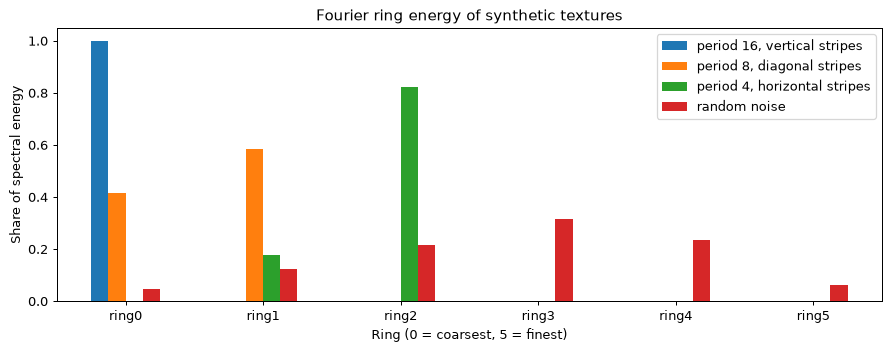

,"period 16, vertical stripes","period 8, diagonal stripes","period 4, horizontal stripes",random noise
ring0,1.0,0.415,0.000,0.046
ring1,0.0,0.585,0.177,0.122
ring2,0.0,0.000,0.823,0.217
ring3,0.0,0.000,0.000,0.317
ring4,0.0,0.000,0.000,0.234
ring5,0.0,0.000,0.000,0.064


In [5]:
# Ring energy of the same images, computed with tx.fourier_texture (32 x 32 tiles, 6 rings).
# mean share of energy in each of 6 frequency rings, per image
ring_tab = pd.DataFrame({name: {k: float(np.nanmean(v)) for k, v in tx.fourier_texture(img, size=32, step=8, n_rings=6).items()}
                         for name, img in synth.items()})  # one column per synthetic image
ax = ring_tab.plot(kind="bar", figsize=(10, 4), rot=0)  # grouped bars: rings on x, one colour per image
ax.set(ylabel="Share of spectral energy", xlabel="Ring (0 = coarsest, 5 = finest)",  # axis labels
       title="Fourier ring energy of synthetic textures")  # and title
plt.tight_layout(); plt.show()  # arrange and draw
# show the table
ring_tab.round(3)

Period 16 (2 cycles per 32-pixel tile) falls entirely in `ring0`, period 8 (4 cycles) mostly in `ring1`
(the diagonal pattern leaks into `ring0`), and period 4 (8 cycles) in `ring2`. Noise spreads across all
rings. The rings extend to the corners of the spectrum, beyond the highest frequency along the axes, so
`ring5` collects only the finest diagonal frequencies and always holds a small share.


Note that the energy fractions include the tile mean (the zero frequency), which always falls in
`ring0`. On real imagery, where most variance is at low frequencies, `ring0` therefore holds most of the
energy, and the information is in how much energy spills into the outer rings.

### Power spectra of real Landsat tiles


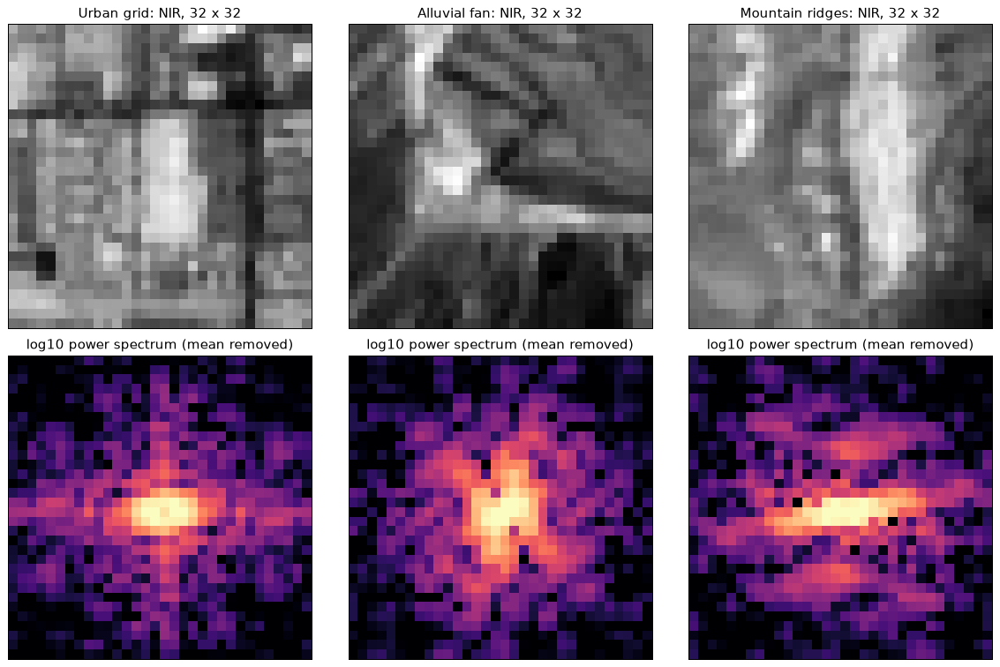

In [6]:
# three 40 x 40 pixel sample boxes (rows, columns) in the study window
BOXES = {"Urban grid": (slice(100, 140), slice(40, 80)),
         "Alluvial fan": (slice(300, 340), slice(270, 310)),  # gravel slopes
         "Mountain ridges": (slice(130, 170), slice(400, 440))}  # rugged terrain
# one colour per box
COLORS = {"Urban grid": "#d7191c", "Alluvial fan": "#fdae61", "Mountain ridges": "#2b83ba"}

fig, axes = plt.subplots(2, 3, figsize=(13, 8.5))  # NIR tiles (top) and their spectra (bottom)
han32 = np.outer(np.hanning(32), np.hanning(32))  # 32 x 32 Hann taper
for k, (name, (ys, xs)) in enumerate(BOXES.items()):  # one column per box
    # the central 32 x 32 pixels of the box
    tile = nir.values[ys.start + 4:ys.start + 36, xs.start + 4:xs.start + 36]
    # power spectrum of the tapered, mean-free tile
    spec = np.abs(np.fft.fftshift(np.fft.fft2((tile - tile.mean()) * han32)))**2
    axes[0, k].imshow(tile, cmap="gray"); axes[0, k].set_title(f"{name}: NIR, 32 x 32")  # the tile
    ls_ = np.log10(spec + 1e-12)  # log power
    # stretched between the 20th and 99.5th percentiles
    axes[1, k].imshow(ls_, cmap="magma", vmin=np.percentile(ls_, 20), vmax=np.percentile(ls_, 99.5))
    axes[1, k].set_title("log10 power spectrum (mean removed)")  # title
for a in axes.ravel():  # no ticks
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()  # arrange and draw

The urban tile has a cross-shaped spectrum with power along both axes and far from the centre: the
north-south and east-west streets repeat every few pixels. The ridge tile has power elongated along the
horizontal frequency axis, perpendicular to its north-south ridges, with secondary peaks that mark the
ridge spacing. The fan tile's power is concentrated near the centre: its texture is coarse and weak.


### Ring energy maps

`tx.fourier_texture(img, size, step, n_rings)` slides a `size` × `size` tile every `step` pixels,
computes the Hann-windowed power spectrum and returns the share of energy in each of `n_rings` rings.
Tiles of 32 × 32 pixels (960 m) resolve periods between 2 and 32 pixels.


fourier_texture: 0.8 s -> ['ring0', 'ring1', 'ring2', 'ring3', 'ring4', 'ring5']


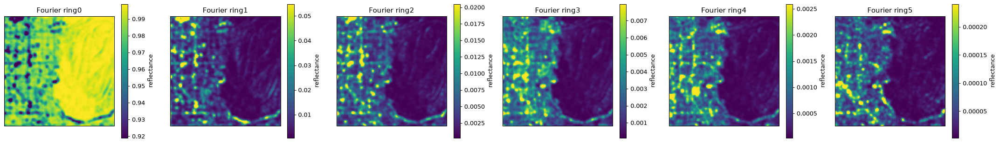

In [7]:
t0 = time.time()  # start the timer
# 32 x 32 tiles every 4 pixels, energy share in 6 rings
four = tx.fourier_texture(nir, size=32, step=4, n_rings=6)
print(f"fourier_texture: {time.time() - t0:.1f} s ->", list(four.data_vars))  # run time and layer names

fig, axes = plt.subplots(1, 6, figsize=(24, 4.3))  # six panels
for ax, f in zip(axes, four.data_vars):  # one panel per ring
    rs.viz.plot_raster(four[f], ax=ax, cmap="viridis", title=f"Fourier {f}")  # draw the ring energy
    ax.set_xticks([]); ax.set_yticks([])  # no ticks
plt.tight_layout(); plt.show()  # arrange and draw

`ring0` holds more than 99% of the energy on the fan and the ridges, against 97% in the city. The city
moves energy into the outer rings: `ring2` holds 0.73% of the energy in the urban box against about
0.06% on the fan and the ridges, more than ten times as much.


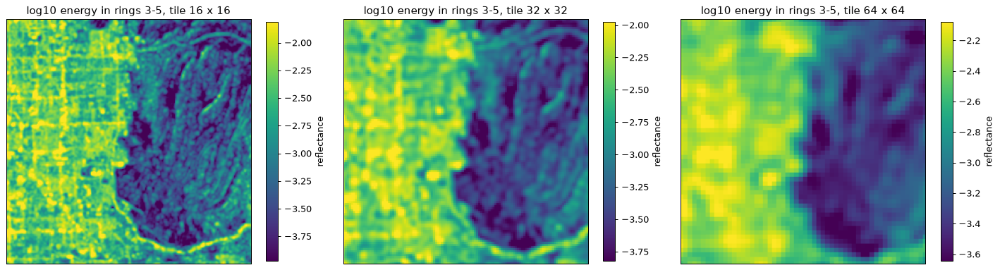

In [8]:
# Tile size controls the trade-off between frequency resolution and spatial detail.
fig, axes = plt.subplots(1, 3, figsize=(16, 5))  # three tile sizes
for ax, s in zip(axes, [16, 32, 64]):  # 16, 32 and 64 pixels
    # step = one eighth of the tile, at least 2
    f = tx.fourier_texture(nir, size=s, step=max(2, s // 8), n_rings=6)
    outer = f["ring3"] + f["ring4"] + f["ring5"]  # energy in the three finest rings (fine texture)
    # on a log scale
    rs.viz.plot_raster(np.log10(outer + 1e-8), ax=ax, cmap="viridis", title=f"log10 energy in rings 3-5, tile {s} x {s}")
    ax.set_xticks([]); ax.set_yticks([])  # no ticks
plt.tight_layout(); plt.show()  # arrange and draw

16 × 16 tiles give sharp boundaries but noisy values and a coarse frequency resolution; 64 × 64 tiles give
stable values but a blocky map in which the city-fan boundary is smeared over 2 km. 32 × 32 is a good
compromise for Landsat.


## Gabor filter bank

### The filters

Below are the real parts of the 12 kernels used in this section: 3 frequencies × 4 orientations.
Frequency is in cycles per pixel, so *f* = 0.1 is a 10-pixel (300 m) period, *f* = 0.25 a 4-pixel
(120 m) period and *f* = 0.4 a 2.5-pixel (75 m) period. In `scikit-image`, the wave of a filter with
θ = 0 runs along the x-axis, so it responds to **vertical** stripes (north-south streets); θ = 90
responds to horizontal stripes.


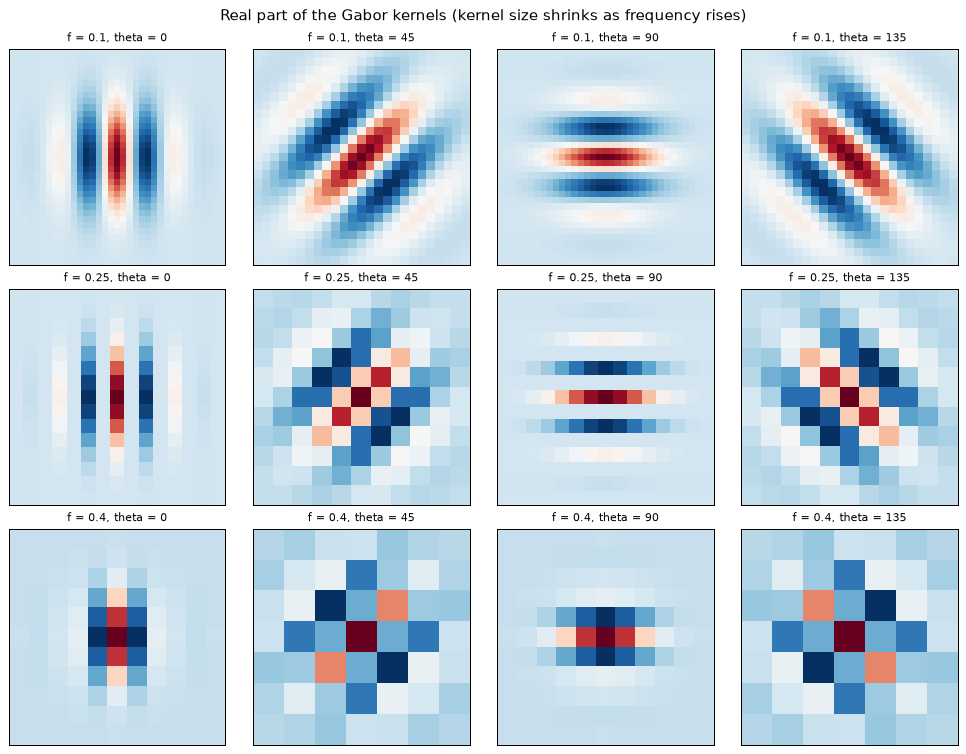

In [9]:
from skimage.filters import gabor_kernel  # Gabor kernels from scikit-image
FREQS, THETAS = (0.1, 0.25, 0.4), (0, 45, 90, 135)  # 3 frequencies (cycles per pixel) x 4 orientations (degrees)
fig, axes = plt.subplots(3, 4, figsize=(11, 8.5))  # one panel per kernel
for i, f in enumerate(FREQS):  # rows: frequency
    for j, t in enumerate(THETAS):  # columns: orientation
        k = np.real(gabor_kernel(f, theta=np.radians(t)))  # real part of the complex kernel
        # show it with its parameters
        axes[i, j].imshow(k, cmap="RdBu_r"); axes[i, j].set_title(f"f = {f}, theta = {t}", fontsize=9)
        axes[i, j].set_xticks([]); axes[i, j].set_yticks([])  # no ticks
plt.suptitle("Real part of the Gabor kernels (kernel size shrinks as frequency rises)")  # overall title
plt.tight_layout(); plt.show()  # arrange and draw

`tx.gabor_texture(img, frequencies, thetas, size)` stretches the band to 0-1 (2nd-98th percentile),
filters it with every (frequency, θ) pair, and pools the response energy in a `size` × `size` window.
Each feature is named `gabor_f<frequency>_t<theta>`.


gabor_texture: 1.3 s, 12 features


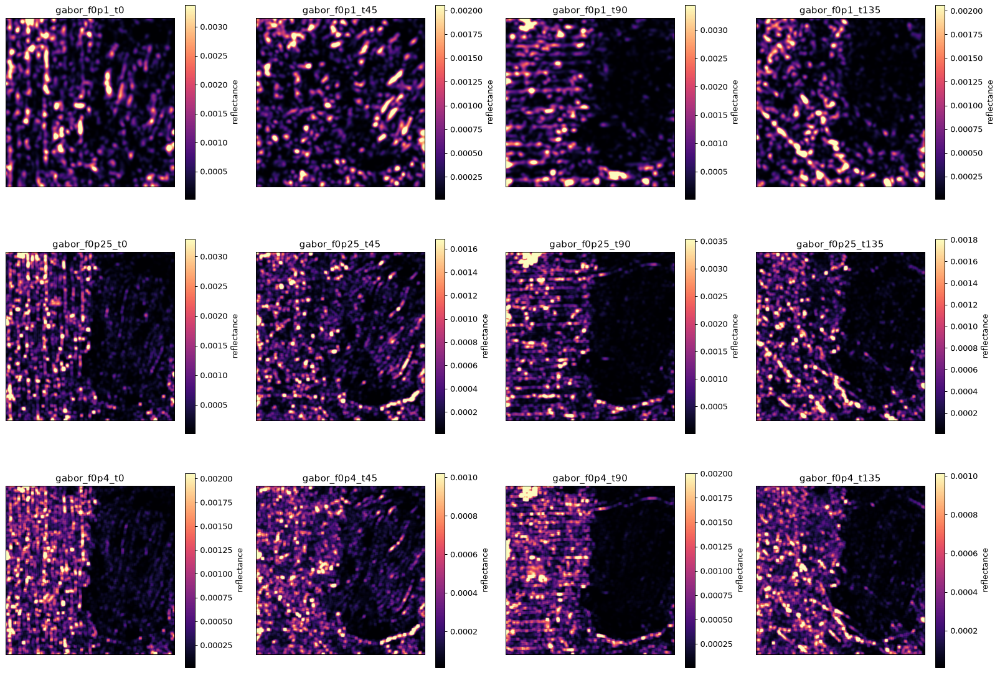

In [10]:
t0 = time.time()  # start the timer
# filter energy for every frequency and orientation, averaged in 9 x 9 windows
gab = tx.gabor_texture(nir, frequencies=FREQS, thetas=THETAS, size=9)
# run time and number of features (3 x 4 = 12)
print(f"gabor_texture: {time.time() - t0:.1f} s, {len(gab.data_vars)} features")

fig, axes = plt.subplots(3, 4, figsize=(18, 13))  # 3 x 4 panels
for ax, f in zip(axes.ravel(), gab.data_vars):  # one panel per filter
    rs.viz.plot_raster(gab[f], ax=ax, cmap="magma", title=f)  # draw the energy
    ax.set_xticks([]); ax.set_yticks([])  # no ticks
plt.tight_layout(); plt.show()  # arrange and draw

θ = 0 lights up the north-south streets and θ = 90 the east-west streets; θ = 45 and θ = 135 respond to
the diagonal boulevard and the curving Wash. The low-frequency filters (*f* = 0.1, 300 m period) respond
to block-sized patterns and to the broader ridges, which appear in θ = 0 and θ = 45; the high-frequency
filters (*f* = 0.4, 75 m) respond almost only in the city. The fan is dark in every filter.


## Haar wavelet decomposition

### The subbands

First we look at the decomposition itself. `tx._haar_step` is the internal helper that performs one
level of the orthonormal 2-D Haar transform; applying it twice gives the classic pyramid of subbands.


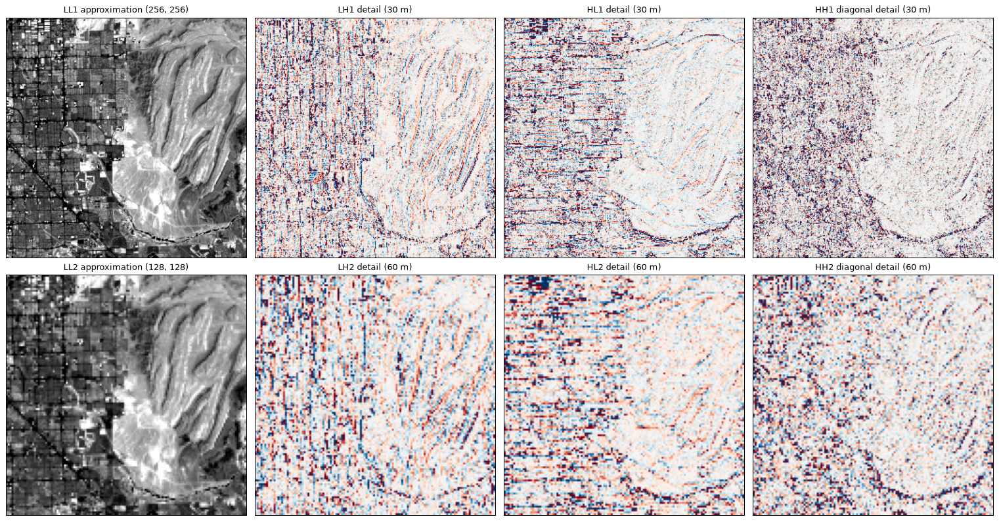

{'LL2': '98.23%', 'detail L2': '0.98%', 'detail L1': '0.79%'} | total / image energy = 1.0


In [11]:
a0 = np.nan_to_num(nir.values, nan=float(nir.mean()))  # the NIR window with NaN replaced by the mean
ll1, lh1, hl1, hh1 = tx._haar_step(a0)  # one Haar step: approximation and three detail bands at half resolution
ll2, lh2, hl2, hh2 = tx._haar_step(ll1)  # a second step on the approximation

def show(ax, a, t, cmap="gray"):  # helper: one panel with a 2-98 % stretch
    # stretch limits, then draw
    lo, hi = np.percentile(a, [2, 98]); ax.imshow(a, cmap=cmap, vmin=lo, vmax=hi); ax.set_title(t, fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])  # no ticks

fig, axes = plt.subplots(2, 4, figsize=(17, 9))  # level 1 (top) and level 2 (bottom)
show(axes[0, 0], ll1, f"LL1 approximation {ll1.shape}")  # smoothed image at level 1
show(axes[0, 1], lh1, "LH1 detail (30 m)", "RdBu_r")  # horizontal detail
show(axes[0, 2], hl1, "HL1 detail (30 m)", "RdBu_r")  # vertical detail
show(axes[0, 3], hh1, "HH1 diagonal detail (30 m)", "RdBu_r")  # diagonal detail
show(axes[1, 0], ll2, f"LL2 approximation {ll2.shape}")  # level 2: approximation
show(axes[1, 1], lh2, "LH2 detail (60 m)", "RdBu_r")  # and its three details
show(axes[1, 2], hl2, "HL2 detail (60 m)", "RdBu_r")
show(axes[1, 3], hh2, "HH2 diagonal detail (60 m)", "RdBu_r")
plt.tight_layout(); plt.show()  # arrange and draw

# Energy budget: the orthonormal transform preserves total energy.
# energy (sum of squares) of each part
e = {"LL2": (ll2**2).sum(), "detail L2": sum((b**2).sum() for b in (lh2, hl2, hh2)),
     "detail L1": sum((b**2).sum() for b in (lh1, hl1, hh1))}  # all level-1 details
tot = sum(e.values())  # total energy of all parts
# shares, and total over the image energy (1 = energy preserved)
print({k: f"{v / tot:.2%}" for k, v in e.items()}, "| total / image energy =", round(tot / (a0[:512, :512]**2).sum(), 6))

`LH` (differences along rows) highlights north-south structures: north-south streets and the ridges.
`HL` (differences along columns) highlights east-west streets. `HH` is high where both change, mostly
in the city. Note that naming conventions for LH and HL differ between textbooks and libraries; check
the orientation on your own data, as here.

The transform is orthonormal, so the total energy is preserved (ratio 1.0). Because the tile mean is in
the approximation, 98% of the energy is in `LL2` and only about 1.8% in the six detail subbands, and
those 1.8% hold all the texture.


`tx.wavelet_texture(img, level, size)` returns the local mean energy of every detail subband, resampled
to full resolution and pooled in a `size` × `size` window: `LH_L1`, `HL_L1`, `HH_L1`, `LH_L2`, ...


wavelet_texture: 0.10 s -> ['LH_L1', 'HL_L1', 'HH_L1', 'LH_L2', 'HL_L2', 'HH_L2', 'LH_L3', 'HL_L3', 'HH_L3']


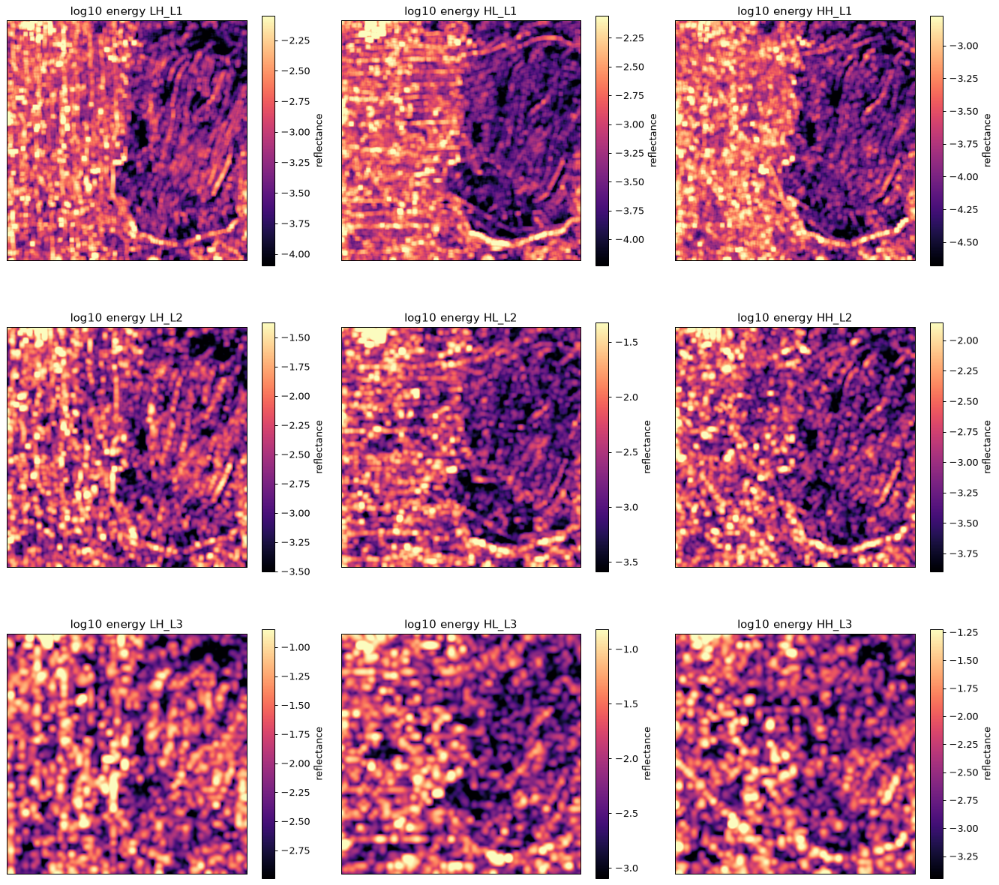

In [12]:
t0 = time.time()  # start the timer
wav = tx.wavelet_texture(nir, level=3, size=9)  # 3 levels; local energy of each detail band in 9 x 9 windows
print(f"wavelet_texture: {time.time() - t0:.2f} s ->", list(wav.data_vars))  # run time and layer names

fig, axes = plt.subplots(3, 3, figsize=(15, 14))  # 3 x 3 panels: level (rows) by orientation (columns)
for ax, f in zip(axes.ravel(), wav.data_vars):  # one panel per layer
    rs.viz.plot_raster(np.log10(wav[f] + 1e-9), ax=ax, cmap="magma", title=f"log10 energy {f}")  # log energy
    ax.set_xticks([]); ax.set_yticks([])  # no ticks
plt.tight_layout(); plt.show()  # arrange and draw

At level 1 the city has 5 to 10 times more detail energy than the fan and the ridges, and the `LH`/`HL`
pair separates the two street directions. At level 2 (60 m) the folds of Frenchman Mountain appear in
`LH_L2`, because the ridges are wider than one pixel. At level 3 (120 m) the maps become blobby and the
contrast between surfaces weakens.


## Application: orientation mapping

The four orientations of the Gabor bank can be combined into two maps for one frequency:

- **Dominant orientation**: the θ with the highest energy.
- **Anisotropy**: (max − min) / (max + min) of the energies across θ, from 0 (isotropic: equal energy
  in all directions) to 1 (all energy in one direction).

Orientation is meaningful only where texture is both strong and anisotropic, so the map is masked where
energy or anisotropy is low.


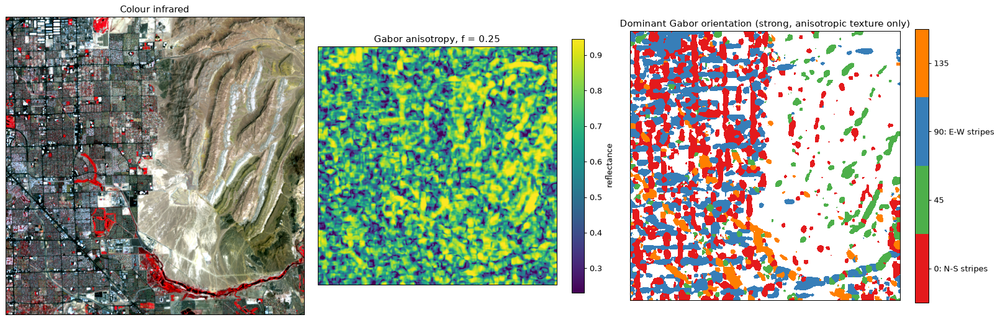

,Urban grid,Alluvial fan,Mountain ridges
theta 0,51%,0%,66%
theta 45,5%,0%,34%
theta 90,44%,91%,0%
theta 135,0%,9%,0%
oriented pixels,89%,10%,11%


In [13]:
f = "0p25"  # use the f = 0.25 filters
# stack the four orientations along a new 'theta' dimension
E = xr.concat([gab[f"gabor_f{f}_t{t}"] for t in THETAS], dim="theta").assign_coords(theta=list(THETAS))
emax, emin = E.max("theta"), E.min("theta")  # strongest and weakest orientation response
aniso = (emax - emin) / (emax + emin + 1e-12)  # 0 = same in every direction, 1 = one direction only
dom = E.argmax("theta").astype(float)  # index of the strongest orientation (0-3)
# keep only strong (above median) and clearly oriented pixels
mask = (emax > float(emax.quantile(0.5))) & (aniso > 0.4)

from matplotlib.colors import ListedColormap  # a four-colour map for the orientations
# red, green, blue, orange
ocmap = ListedColormap(["#e41a1c", "#4daf4a", "#377eb8", "#ff7f00"])
fig, axes = plt.subplots(1, 3, figsize=(18, 6))  # three panels
rs.viz.plot_rgb(sub, "false_color", ax=axes[0], title="Colour infrared")  # reference image
rs.viz.plot_raster(aniso, ax=axes[1], cmap="viridis", title="Gabor anisotropy, f = 0.25")  # anisotropy
# dominant orientation where the mask is true
im = axes[2].imshow(dom.where(mask), cmap=ocmap, vmin=-0.5, vmax=3.5, interpolation="nearest")
cb = plt.colorbar(im, ax=axes[2], ticks=range(4), fraction=0.046)  # colour bar with one tick per orientation
cb.ax.set_yticklabels(["0: N-S stripes", "45", "90: E-W stripes", "135"])  # label the ticks
axes[2].set_title("Dominant Gabor orientation (strong, anisotropic texture only)")  # title
for a in axes:  # no ticks
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()  # arrange and draw

# Share of masked pixels in each orientation, per box.
tab = {}  # orientation shares per box
for name, (ys, xs) in BOXES.items():  # loop over the boxes
    d = dom.where(mask).isel(y=ys, x=xs).values.ravel()  # orientations of the masked pixels in the box
    d = d[np.isfinite(d)].astype(int)  # drop unmasked pixels
    # share of each orientation
    tab[name] = {f"theta {t}": (d == k).mean() if d.size else np.nan for k, t in enumerate(THETAS)}
    tab[name]["oriented pixels"] = d.size / 1600  # share of the box's 1,600 pixels that are oriented
# show as percentages
pd.DataFrame(tab).map(lambda v: f"{v:.0%}")

In the urban box, half of the oriented pixels respond most to θ = 0 and 44% to θ = 90: the two
directions of the street grid. On the ridges, 66% respond to θ = 0 and 34% to θ = 45, consistent with
ridges that strike between north and north-east. Only 10% of the fan pixels pass the mask: the fan has
little oriented texture. Anisotropy alone is noisy (it is just as high on the fan, 0.74, as in the city,
0.66) because it is a ratio of small numbers where energy is low; the energy mask is essential.


## Application: texture signatures and clustering


Three 40 × 40 pixel boxes (1.2 × 1.2 km), chosen by eye on the false-colour image, are used to compare
texture signatures:

| Box | Rows | Columns | Surface |
|---|---|---|---|
| Urban grid | 100-140 | 40-80 | Residential blocks and streets |
| Alluvial fan | 300-340 | 270-310 | Smooth bare desert soil |
| Mountain ridges | 130-170 | 400-440 | Folded sedimentary ridges of Frenchman Mountain |


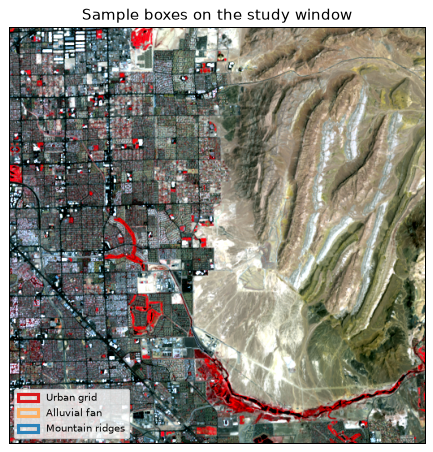

In [14]:
# three 40 x 40 pixel sample boxes (rows, columns) in the study window
BOXES = {"Urban grid": (slice(100, 140), slice(40, 80)),
         "Alluvial fan": (slice(300, 340), slice(270, 310)),  # gravel slopes east of the city
         "Mountain ridges": (slice(130, 170), slice(400, 440))}  # rugged terrain
# one colour per box
COLORS = {"Urban grid": "#d7191c", "Alluvial fan": "#fdae61", "Mountain ridges": "#2b83ba"}

fig, ax = plt.subplots(figsize=(6, 6))  # one panel
# colour infrared background
rs.viz.plot_rgb(sub, "false_color", ax=ax, title="Sample boxes on the study window")
for name, (ys, xs) in BOXES.items():  # draw each box
    # x = column start, y = row start, then width and height
    ax.add_patch(Rectangle((xs.start, ys.start), xs.stop - xs.start, ys.stop - ys.start,
                           # outline only, labelled for the legend
                           fill=False, ec=COLORS[name], lw=2.5, label=name))
ax.legend(loc="lower left", fontsize=8); ax.set_xticks([]); ax.set_yticks([])  # legend, no ticks
plt.show()  # draw

In [15]:
from sklearn.cluster import KMeans  # k-means clustering
from sklearn.preprocessing import StandardScaler  # standardise features to mean 0, std 1
from scipy.ndimage import generic_filter  # moving-window filter for the speckle measure

def box_means(ds):  # average feature values per sample box
    """Mean of every variable of `ds` inside each sample box."""
    # rows = features, columns = boxes
    return pd.DataFrame({name: {v: float(ds[v].isel(y=ys, x=xs).mean()) for v in ds.data_vars}
                         for name, (ys, xs) in BOXES.items()})

def plot_signatures(sig, title):  # compare the boxes feature by feature
    """Bar chart of box means, min-max scaled per feature across the three boxes."""
    # scale each feature to 0-1 across the three boxes
    norm = sig.sub(sig.min(axis=1), axis=0).div(sig.max(axis=1) - sig.min(axis=1), axis=0)
    fig, ax = plt.subplots(figsize=(max(7, 0.75 * len(norm)), 4.5))  # width grows with the number of features
    x = np.arange(len(norm))  # one group of bars per feature
    for k, name in enumerate(norm.columns):  # one bar per box, shifted sideways
        ax.bar(x + (k - 1) * 0.27, norm[name], width=0.27, color=COLORS[name], label=name)  # draw the bars
    ax.set_xticks(x, norm.index, rotation=45, ha="right")  # feature names, rotated
    ax.set(ylabel="Relative value (0 = lowest box, 1 = highest)", title=title)  # labels
    ax.legend(); plt.tight_layout(); plt.show()  # legend and draw

def kmeans_map(ds, k=5, n_fit=40000, seed=0):  # unsupervised map from a set of layers
    """Standardize the layers, fit k-means on a random pixel sample and label every pixel."""
    df = ds.to_dataframe(dim_order=["y", "x"])[list(ds.data_vars)]  # pixels as rows, layers as columns
    ok = df.notna().all(axis=1).values  # pixels without missing values
    X = StandardScaler().fit_transform(df[ok].values)  # standardise so every layer weighs the same
    rng = np.random.default_rng(seed)  # random sample generator
    # fit on at most 40,000 random pixels (faster)
    km = KMeans(k, n_init=10, random_state=seed).fit(X[rng.choice(len(X), min(n_fit, len(X)), replace=False)])
    lab = np.full(ok.size, np.nan); lab[ok] = km.predict(X)  # label all valid pixels; others stay NaN
    # labels back on the image grid
    return xr.DataArray(lab.reshape(ds.sizes["y"], ds.sizes["x"]), coords={"y": ds.y, "x": ds.x}, dims=("y", "x"))

def speckle(lab):  # how noisy a cluster map is
    """Share of pixels whose label differs from the majority label of their 3 x 3 neighbourhood."""
    a = np.nan_to_num(lab.values, nan=-1).astype(int)  # NaN -> -1 so the labels are integers
    # majority label in each 3 x 3 window
    mode = generic_filter(a, lambda v: np.bincount(v.astype(int) + 1).argmax() - 1, size=3)
    return float((a != mode).mean())  # share of pixels that differ from their neighbourhood majority

def box_purity(lab):  # how uniform each box is in a cluster map
    """Share of each box's pixels that fall in the box's most common cluster."""
    out = {}  # one value per box
    for name, (ys, xs) in BOXES.items():  # loop over the boxes
        v = lab.isel(y=ys, x=xs).values.ravel()  # labels inside the box
        v = v[np.isfinite(v)].astype(int)  # drop missing labels
        out[name] = np.bincount(v).max() / v.size  # share of the most common label
    return out  # dictionary box -> purity

# Spectral layers used as the baseline in every notebook: the four bands and NDVI.
# normalised difference vegetation index
ndvi = ((sub["nir"] - sub["red"]) / (sub["nir"] + sub["red"])).rename("NDVI")
spectral = xr.Dataset({**{b: sub[b] for b in BANDS}, "NDVI": ndvi})  # four bands plus NDVI

In [16]:
# average the four orientations for each Gabor frequency
gab_mean = {fr: sum(gab[f"gabor_f{fr}_t{t}"] for t in THETAS) / 4 for fr in ["0p1", "0p25", "0p4"]}
tr_feats = xr.Dataset({  # the transform-based layers of this notebook
    # coarse, middle and fine Fourier rings
    "Fourier ring0": four["ring0"], "Fourier ring2": four["ring2"], "Fourier ring5": four["ring5"],
    # Gabor energy at three frequencies
    "Gabor f0.1 (mean)": gab_mean["0p1"], "Gabor f0.25 (mean)": gab_mean["0p25"], "Gabor f0.4 (mean)": gab_mean["0p4"],
    "Gabor anisotropy": aniso,  # how directional the texture is
    # level-1 wavelet details
    "Wavelet LH_L1": wav["LH_L1"], "Wavelet HL_L1": wav["HL_L1"], "Wavelet HH_L1": wav["HH_L1"],
    "Wavelet HH_L2": wav["HH_L2"], "Wavelet HH_L3": wav["HH_L3"],  # diagonal detail at levels 2 and 3
})
sig = box_means(tr_feats)  # mean of each feature in each box
# show with three significant digits
sig.apply(lambda r: r.map(lambda v: f"{v:.3g}"), axis=1)

,Urban grid,Alluvial fan,Mountain ridges
Fourier ring0,0.972,0.997,0.997
Fourier ring2,0.00729,0.000664,0.000564
Fourier ring5,9.22e-05,8.86e-06,8.6e-06
Gabor f0.1 (mean),0.000881,0.00016,0.000261
Gabor f0.25 (mean),0.000764,0.000111,0.000118
Gabor f0.4 (mean),0.000504,6.26e-05,6.91e-05
Gabor anisotropy,0.664,0.742,0.698
Wavelet LH_L1,0.00277,0.000337,0.000554
Wavelet HL_L1,0.00225,0.000347,0.000221
Wavelet HH_L1,0.000422,9e-05,7.09e-05


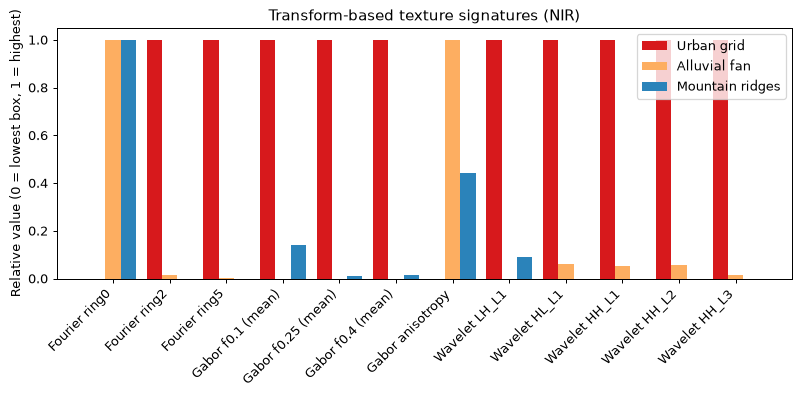

In [17]:
plot_signatures(sig, "Transform-based texture signatures (NIR)")  # bar chart of the box signatures

Gabor energy, outer Fourier rings and wavelet detail are 5 to 10 times higher in the city than on the
natural surfaces. The fan and the ridges are nearly identical on most energies. Gabor anisotropy is
similar in all three boxes and does not separate them on its own.


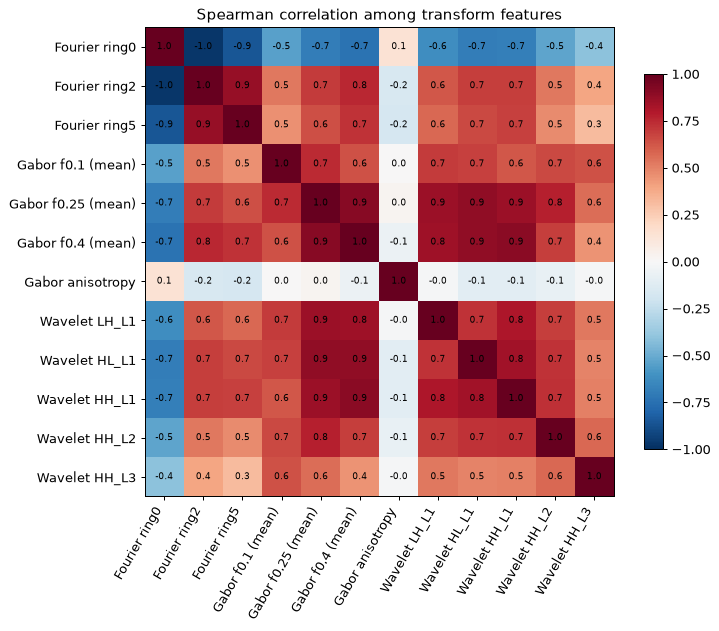

In [18]:
# Correlation among the transform features.
tdf = tr_feats.to_dataframe()[list(tr_feats.data_vars)].dropna()  # pixels as rows, features as columns
# rank correlation is robust to the skewed energies
tc = tdf.corr(method="spearman")   # rank correlation: insensitive to the skewed energy values
names = list(tr_feats.data_vars)  # feature names for the axes
fig, ax = plt.subplots(figsize=(8.5, 7))  # one panel
im = ax.imshow(tc, cmap="RdBu_r", vmin=-1, vmax=1)  # the correlation matrix
# labels on both axes
ax.set_xticks(range(len(names)), names, rotation=60, ha="right"); ax.set_yticks(range(len(names)), names)
for i in range(len(names)):  # write each value in its cell
    for j in range(len(names)):  # columns
        ax.text(j, i, f"{tc.iloc[i, j]:.1f}", ha="center", va="center", fontsize=7)  # one decimal
# colour bar and title
plt.colorbar(im, shrink=0.8); ax.set_title("Spearman correlation among transform features")
plt.tight_layout(); plt.show()  # arrange and draw

`ring0` is almost perfectly anti-correlated with the outer rings (ρ ≈ −0.9 to −1), so one of them is
enough. Gabor energy at *f* = 0.25 and 0.4 and the level-1 wavelet energies form a tight group (ρ = 0.8 to
0.9): they all measure fine-scale roughness. Gabor anisotropy is independent of everything else.


### Does this family add information? A clustering test

Texture is useful only if it carries information that the spectral bands do not. We run k-means with
5 clusters on (a) the four bands and NDVI only and (b) the same spectral layers plus this notebook's
texture features, all standardized. Two numbers summarize the maps:

- **Speckle**: the share of pixels whose cluster differs from the majority of their 3 × 3
  neighbourhood (lower = more spatially coherent).
- **Purity**: the share of pixels in each sample box that fall in that box's most common cluster
  (higher = the surface is mapped as one unit).


In [19]:
def compare_clusterings(texture_ds, label):  # clustering with and without the texture layers
    """k-means on spectral layers only vs spectral + texture layers; maps, speckle and box purity."""
    k_spec = kmeans_map(spectral)  # five spectral layers
    k_both = kmeans_map(xr.merge([spectral, texture_ds], compat="override"))  # spectral plus texture layers
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))  # three panels
    rs.viz.plot_rgb(sub, "false_color", ax=axes[0], title="Colour infrared")  # reference image
    for ax, lab, t in zip(axes[1:], [k_spec, k_both],  # the two cluster maps with their titles
                          ["k-means, spectral only (5 layers)",
                           f"k-means, spectral + {label} ({5 + len(texture_ds.data_vars)} layers)"]):
        ax.imshow(lab, cmap="Set2", interpolation="nearest")  # one colour per cluster
        ax.set_title(f"{t}\nspeckle = {speckle(lab):.1%}")  # title with the speckle share
    for a in axes:  # no pixel ticks
        a.set_xticks([]); a.set_yticks([])
    plt.tight_layout(); plt.show()  # arrange and draw
    return pd.DataFrame({"spectral only": box_purity(k_spec),  # box purity of both maps, as percentages
                         # format each value as a percentage
                         f"spectral + {label}": box_purity(k_both)}).map(lambda v: f"{v:.0%}")

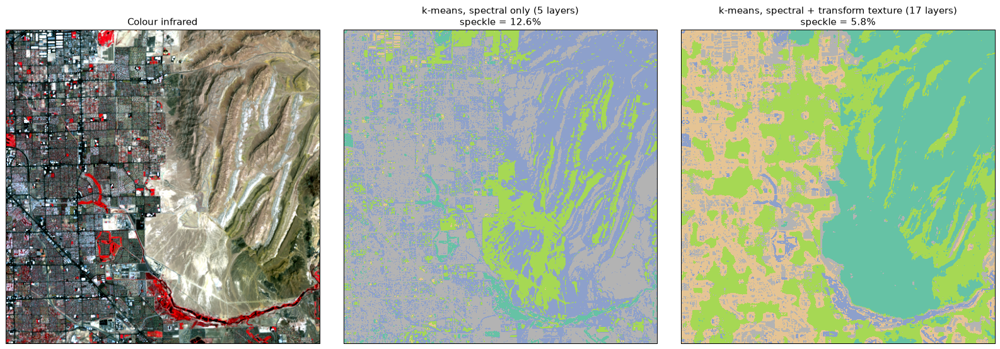

,spectral only,spectral + transform texture
Urban grid,53%,60%
Alluvial fan,58%,97%
Mountain ridges,66%,95%


In [20]:
# Energies are heavy-tailed: cluster on their logarithms.
tr_km = tr_feats.copy()  # a copy used only for clustering
for v in tr_km.data_vars:  # every layer except anisotropy (already 0-1)
    if v not in ("Gabor anisotropy",):
        tr_km[v] = np.log10(tr_feats[v] + 1e-9)  # log energy; 1e-9 avoids log(0)
compare_clusterings(tr_km, "transform texture")  # maps, speckle and box purity

Adding transform texture reduces speckle from 12.6% to 5.8% and raises purity from 53% to 60% in the
city, 58% to 97% on the fan and 66% to 95% on the ridges. As with statistical texture, the fan and the
ridges merge into one smooth natural-desert cluster, and the city splits into two block types.


In [21]:
OUT = Path("outputs") / "texture"  # output folder for texture rasters
OUT.mkdir(parents=True, exist_ok=True)  # create it if needed
# Dataset -> one multi-band GeoTIFF (one band per feature)
tr_feats.to_array("feature").astype("float32").rio.write_crs(ls.rio.crs).rio.to_raster(OUT / "nir_transform_texture.tif")
with rasterio.open(OUT / "nir_transform_texture.tif") as src:  # read the file back to check it
    # number of bands, size and CRS
    print(f"nir_transform_texture.tif: {src.count} bands, {src.width} x {src.height}, {src.crs}")

nir_transform_texture.tif: 12 bands, 512 x 512, EPSG:32611


## Summary and exercises

**Key points**

- Transform-based methods describe texture by **frequency** (how fine), **orientation** (which way)
  and **scale** (at which resolution).
- The Fourier spectrum of a tile shows the period and direction of repeating patterns; ring energy is a
  rotation-invariant summary of coarseness. Tile size trades frequency resolution against spatial
  detail.
- A Gabor bank gives every pixel its own frequency-orientation description and can map the dominant
  direction of streets, ridges, crop rows or dunes.
- Haar wavelets split detail into octaves of scale and three orientations at almost no computational
  cost; level 1 captures 30 m detail, level 2 60 m and level 3 120 m.
- Most transform energies are strongly skewed; use their logarithms in statistics and models.

**`geolattice.rsense` functions used:** `rs.read`, `rs.optical.scale`, `rs.viz.plot_rgb`, `rs.viz.plot_raster`,
`tx.fourier_texture`, `tx.gabor_texture`, `tx.wavelet_texture`.

**Exercises**

1. Add θ = 22.5°, 67.5°, 112.5° and 157.5° to the Gabor bank. Does the orientation map of the ridges
   become more precise?
2. Use `tx.fourier_texture` with 12 rings on 64 × 64 tiles and plot the mean ring spectrum of each
   sample box. At what period does the city peak?
3. Compute wavelet texture to level 4 (240 m). At which level do the city and the ridges differ most?
4. Repeat the orientation mapping on the red band. Are the dominant orientations the same?
5. Apply `tx.gabor_texture` to an agricultural Landsat scene with centre-pivot or row crops, and map the
   row direction of each field.

**References**

- Daugman, J.G. (1985). Uncertainty relation for resolution in space, spatial frequency, and orientation
  optimized by two-dimensional visual cortical filters. *JOSA A*, 2(7), 1160-1169.
- Gabor, D. (1946). Theory of communication. *Journal of the IEE*, 93(26), 429-457.
- Jain, A.K. and Farrokhnia, F. (1991). Unsupervised texture segmentation using Gabor filters.
  *Pattern Recognition*, 24(12), 1167-1186.
- Mallat, S.G. (1989). A theory for multiresolution signal decomposition: the wavelet representation.
  *IEEE TPAMI*, 11(7), 674-693.
- Rosenfeld, A. and Troy, E.B. (1970). Visual texture analysis. *Conference Record of the Symposium on
  Feature Extraction and Selection in Pattern Recognition*, IEEE, 115-124.
- Weszka, J.S., Dyer, C.R. and Rosenfeld, A. (1976). A comparative study of texture measures for terrain
  classification. *IEEE Transactions on Systems, Man, and Cybernetics*, SMC-6(4), 269-285.

**Previous:** [Statistical and structural texture](09_07_01_texture_analysis_of_landsat_imagery_statistical_and_structural_methods.ipynb) ·
**Next:** [Local pattern-based texture](09_07_03_texture_analysis_of_landsat_imagery_local_pattern_based_methods_lbp.ipynb).
